Le but de ce notebook est de creer une Dataset chronologique, Leakage-Free et pret a etre utiliser par les modèles qu'on va réaliser

In [46]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [32]:
DATA_PATH = Path(r"C:\Users\rayan\Downloads\Datasets (1)\Datasets")

clients = pd.read_csv(DATA_PATH / "clients.csv")

qualifications = pd.read_csv(DATA_PATH / "qualifications.csv")

gestionnaires = pd.read_csv(DATA_PATH / "gestionnaires.csv")

promesses = pd.read_csv(DATA_PATH / "promesses.csv")

client_history = pd.read_csv(DATA_PATH / "client_history_features.csv")

debt_features = pd.read_csv(DATA_PATH / "debt_features.csv")

In [33]:
qualifications["date_qualification"] = pd.to_datetime(
    qualifications["date_qualification"]
)

if "date_promesse" in promesses.columns:
    promesses["date_promesse"] = pd.to_datetime(
        promesses["date_promesse"]
    )

if "date_1ere_avance" in promesses.columns:
    promesses["date_1ere_avance"] = pd.to_datetime(
        promesses["date_1ere_avance"]
    )

construction du cible: 
Une qualification est positive si elle existe dans la table Promesses 

In [34]:
dataset = qualifications.merge(

    promesses[["id_qualification"]],

    on="id_qualification",

    how="left",

    indicator=True

)

dataset["target"] = (

    dataset["_merge"]=="both"

).astype(int)

dataset.drop(columns="_merge", inplace=True)

dataset["target"].value_counts()

target
0    12443
1      672
Name: count, dtype: int64

merge infos client 

In [35]:
dataset = dataset.merge(

    clients,

    on="id_client",

    how="left"

)

print(dataset.shape)

(13115, 13)


Merge features Historique

In [36]:
dataset = dataset.merge(
    client_history,
    on=["id_qualification", "id_client"],
    how="left",
    suffixes=("", "_history")
)

print(dataset.shape)

(13115, 26)


Merge features de credit

In [37]:
dataset = dataset.merge(

    debt_features,

    on="id_client",

    how="left"

)

print(dataset.shape)

(13115, 40)


Merge des information du gestionnaire

In [38]:
dataset = dataset.merge(

    gestionnaires[

        [

            "id_gestionnaire",

            "specialisation",

            "ville",

            "region"

        ]

    ],

    on="id_gestionnaire",

    how="left",

    suffixes=("","_gestionnaire")

)

print(dataset.shape)

(13115, 43)


VERIFICATION DES MERGES

In [39]:
print("Rows :", len(dataset))

print()

print("Unique qualifications :")

print(dataset["id_qualification"].nunique())

print()

print("Unique clients :")

print(dataset["id_client"].nunique())

Rows : 13115

Unique qualifications :
13115

Unique clients :
304


VERIFICATION DES SVALEURS MANQUANTES 

In [40]:
missing = (

    dataset

    .isna()

    .sum()

    .sort_values(

        ascending=False

    )

)

missing = missing[missing>0]

display(missing)

Series([], dtype: int64)

DETECTION DES DOUBLONS

In [41]:
duplicates = dataset.duplicated(

    subset="id_qualification"

).sum()

print("Duplicate qualifications :", duplicates)

Duplicate qualifications : 0


GESTION DU LEAKAGE : On supprime les variables qui reléve le future

In [42]:
leakage_columns = [

    "id_promesse",

    "date_promesse",

    "date_1ere_avance"

]

dataset.drop(

    columns=[

        c

        for c in leakage_columns

        if c in dataset.columns

    ],

    inplace=True

)

Verification de la logique Chronologique 

In [43]:
checks = {

"Previous promises > Previous contacts":

(dataset["previous_promises"]>

dataset["previous_contacts"]).sum(),

"Negative days since previous":

(dataset["days_since_previous_contact"]<0).sum()

}

checks

{'Previous promises > Previous contacts': np.int64(0),
 'Negative days since previous': np.int64(304)}

les categories de nos features

In [44]:
identifier_columns = [

"id_client",

"id_qualification",

"id_gestionnaire"

]

target_column = "target"

categorical_columns = dataset.select_dtypes(

include=["object","category"]

).columns.tolist()

numeric_columns = dataset.select_dtypes(

include=np.number

).columns.tolist()

numeric_columns.remove(target_column)

for col in identifier_columns:

    if col in numeric_columns:

        numeric_columns.remove(col)

print("Categorical :",len(categorical_columns))

print("Numeric :",len(numeric_columns))

Categorical : 19
Numeric : 19


C:\Users\rayan\AppData\Local\Temp\ipykernel_58280\690730365.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = dataset.select_dtypes(


SUMMARY

In [45]:
display(dataset.head())

print(dataset.shape)

print()

display(dataset.describe(include="all").T)

,id_qualification,id_client,date_qualification,type,statut,target,nom,prenom,specialite,adresse,...,debt_income_ratio,monthly_effort,financial_pressure,delay_category,credit_category,high_remaining_debt,high_debt_burden,specialisation,ville_gestionnaire,region_gestionnaire
0,3273,94,2025-09-12,SMS,Joignable,0,Rousseau,Madeleine,Chauffeur,"85 Boulevard Abdelmoumen, Oujda",...,13.145603,0.468056,7.691685,High,Good,1,1,Telephonique,Fès,Fès-Meknès
1,12310,294,2024-06-21,Deplacement,Joignable,0,Anderson,Monique,Fermier,"39 Boulevard Zerktouni, Tanger",...,5.263302,0.222820,3.453505,High,Very Low,1,1,Terrain,Tanger,Tanger-Tétouan-Al Hoceïma
2,878,28,2024-07-24,Deplacement,Joignable,0,Michel,Nicole,Consultant,"8 Rue Allal Ben Abdellah, Safi",...,0.476602,0.199278,0.031663,High,Very Low,0,0,Terrain,Marrakech,Marrakech-Safi
3,1490,29,2024-03-24,Deplacement,Joignable,0,Roux,Daniel,Comptable,"120 Boulevard Zerktouni, Safi",...,4.966769,0.440387,0.933602,High,Low,0,1,Terrain,Marrakech,Marrakech-Safi
4,2861,62,2025-12-18,Email,En cours,0,Garcia,Nathalie,Banquier,"110 Avenue des FAR, Meknès",...,4.816299,0.157661,2.452176,Medium,Good,1,1,Telephonique,Meknès,Fès-Meknès


(13115, 43)



,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id_qualification,13115.0,NaN,NaN,NaN,6558.0,1.0,3279.5,6558.0,9836.5,13115.0,3786.118725
id_client,13115.0,NaN,NaN,NaN,149.837286,1.0,83.0,140.0,218.0,304.0,89.382023
date_qualification,13115,NaN,NaN,NaN,2024-12-29 12:55:10.407929,2024-01-01 00:00:00,2024-07-01 00:00:00,2024-12-28 00:00:00,2025-07-01 00:00:00,2025-12-31 00:00:00,NaN
type,13115,4,Deplacement,5857,NaN,NaN,NaN,NaN,NaN,NaN,NaN
statut,13115,3,Joignable,5568,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target,13115.0,NaN,NaN,NaN,0.051239,0.0,0.0,0.0,0.0,1.0,0.220493
nom,13115,40,David,802,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prenom,13115,30,Marguerite,715,NaN,NaN,NaN,NaN,NaN,NaN,NaN
specialite,13115,24,Artisan,826,NaN,NaN,NaN,NaN,NaN,NaN,NaN
adresse,13115,303,"109 Avenue des FAR, Béni Mellal",119,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Equiliberage de cible

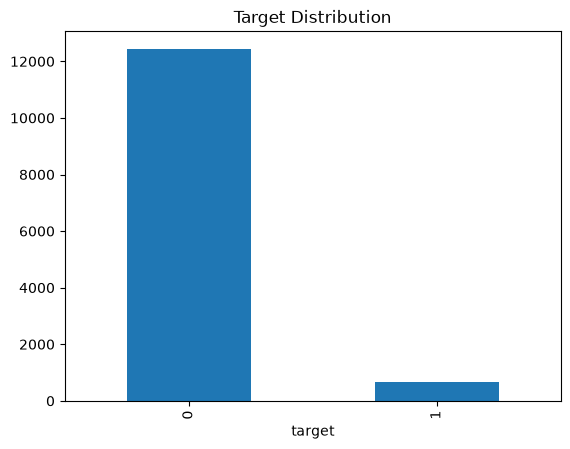

target
0    0.948761
1    0.051239
Name: proportion, dtype: float64


In [47]:


dataset["target"].value_counts().plot(

kind="bar"

)

plt.title("Target Distribution")

plt.show()

print(

dataset["target"]

.value_counts(normalize=True)

)

now we know we have an imbalanced binary classification problem

On utilisera la stratification aprés

In [48]:
dataset.to_csv(

DATA_PATH/"final_dataset.csv",

index=False,

encoding="utf-8-sig"

)

print("Saved successfully.")

print(DATA_PATH/"final_dataset.csv")

Saved successfully.
C:\Users\rayan\Downloads\Datasets (1)\Datasets\final_dataset.csv
